# Model 08 · What excuse will I make tomorrow?
8-class classifier. The model predicts the excuse *category*; the website picks the wording.

In [1]:
import sys
sys.path.insert(0, "../_shared")
try:
    import kit
except ImportError:
    from google.colab import files; files.upload(); import kit
from kit import *

## 1 · Dataset generator

In [2]:
CLASSES = ["github", "internet", "laptop", "family", "forgot", "almost", "submitted", "other"]
WEATHER = ["sunny", "rainy", "stormy", "hot", "cold"]
def generate(n=12000, seed=SEED):
    r = np.random.default_rng(seed)
    d = pd.DataFrame({"hours_left": np.round(np.clip(np.exp(r.normal(2.8, 1.2, n)), 1, 168)), "sleep": np.round(np.clip(r.normal(6.3, 1.5, n), 2, 10), 1),
        "weather": r.choice(WEATHER, n, p=[.35, .2, .1, .25, .1]), "motivation": r.integers(0, 11, n),
        "unfinished": np.clip(r.poisson(4, n), 0, 15), "strictness": r.choice([1, 2, 3, 4, 5], n, p=[.1, .2, .35, .25, .1])})
    wet = d.weather.isin(["rainy", "stormy"]).astype(float); hot = (d.weather == "hot").astype(float)
    s, mo, u, h, sl = d.strictness, d.motivation, d.unfinished, d.hours_left, d.sleep
    U = np.column_stack([
        0.4 + 0.35 * (s - 3) + 0.03 * mo,
        0.0 + 1.3 * wet + 0.3 * (h < 12) + 0.8 * (d.weather == "stormy") * (h < 12),
        -0.2 + 0.7 * hot + 0.04 * u + 0.3 * (sl < 5),
        -0.4 + 0.4 * (s - 3) + 0.5 * (h < 6),
        -0.3 + 0.28 * (5 - mo) + 0.12 * u + 0.4 * (sl < 5),
        -0.1 + 0.7 * (u <= 3) + 0.1 * mo + 0.4 * (h > 48),
        -0.3 + 0.7 * (s <= 2) + 0.05 * u + 0.4 * (s <= 2) * (u >= 6),
        np.full(n, 0.3)])
    U = 2.0 * U
    y = sample_categorical(softmax(U + r.normal(0, 0.4, U.shape)), r)
    d["excuse"] = np.array(CLASSES)[y]; d["oracle_hit"] = (softmax(U).argmax(1) == y).astype(int); return d

In [3]:
df = generate(12000); df.drop(columns="oracle_hit").to_csv("dataset.csv", index=False)
print(df.shape, "| oracle accuracy:", round(df.oracle_hit.mean(), 3)); df.excuse.value_counts(normalize=True).round(3)

(12000, 8) | oracle accuracy: 0.475


excuse
almost       0.253
internet     0.181
forgot       0.174
github       0.146
submitted    0.076
laptop       0.071
other        0.069
family       0.029
Name: proportion, dtype: float64

## 2 · Cleaning + EDA

nulls: 0 | duplicates: 8


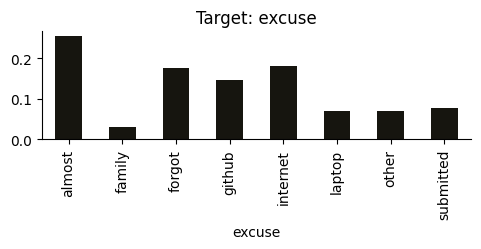

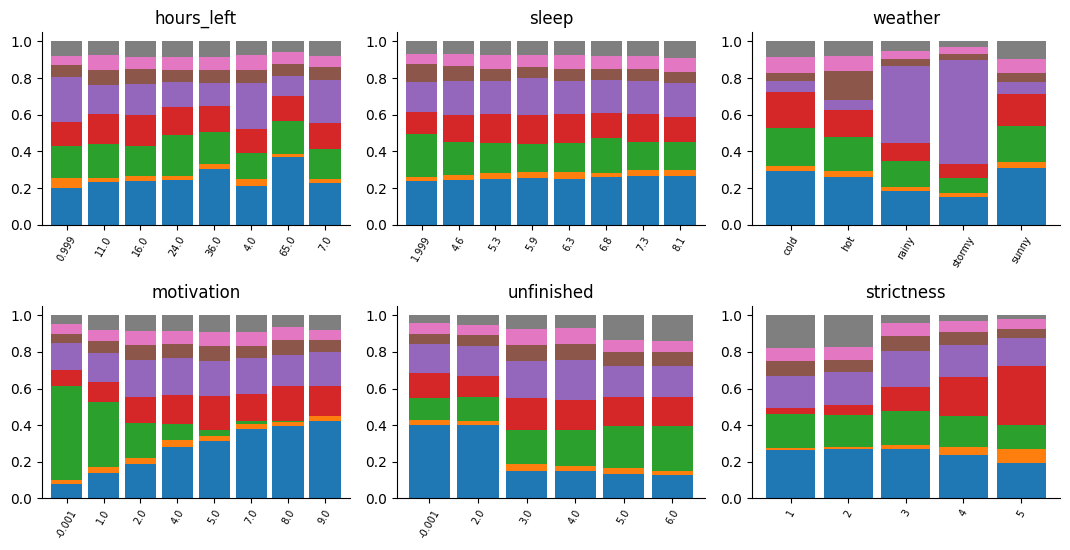

In [4]:
print("nulls:", int(df.isna().sum().sum()), "| duplicates:", int(df.duplicated().sum()))
INPUTS = [Num("hours_left", 0, 168, "log1p"), Num("sleep", 0, 12), Cat("weather", WEATHER), Num("motivation", 0, 10), Num("unfinished", 0, 15), Num("strictness", 1, 5)]
RAW = [s["name"] for s in INPUTS]; eda(df, "excuse", RAW, "multiclass", 3)

## 3 · Features, split, train

In [5]:
IDX = {c: i for i, c in enumerate(CLASSES)}
fz = Featurizer(INPUTS); tr, va, te = split3(df, "excuse")
Xtr, Xva, Xte = fz.transform(tr), fz.transform(va), fz.transform(te)
ytr, yva, yte = (x.excuse.map(IDX).to_numpy() for x in (tr, va, te))
best, best_name, table = train_classifier(Xtr, ytr, Xva, yva, depth=9, leaf=30)
print("selected:", best_name); table.round(4)

selected: Logistic Regression


,model,val_log_loss,val_accuracy
0,Logistic Regression,1.5019,0.4733
1,Random Forest,1.5239,0.4661


## 4 · Test evaluation + importance

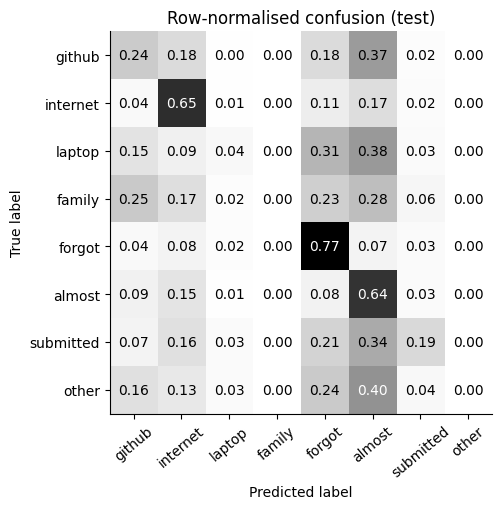

{'accuracy': 0.4678,
 'macro_f1': 0.2906,
 'log_loss': 1.5308,
 'top3_accuracy': 0.7717,
 'oracle_accuracy': 0.4833}

In [6]:
m = report_multiclass(best, Xte, yte, CLASSES); m["oracle_accuracy"] = round(float(te.oracle_hit.mean()), 4); m

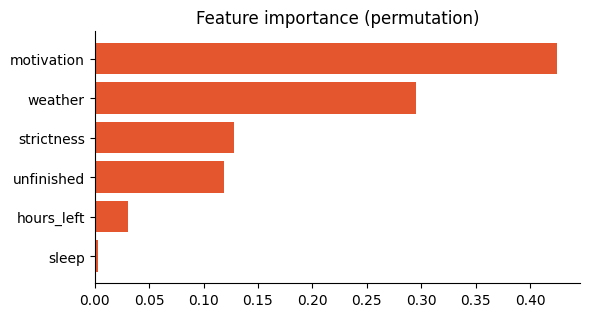

{'motivation': 0.4244,
 'weather': 0.2952,
 'strictness': 0.1282,
 'unfinished': 0.1185,
 'hours_left': 0.0305,
 'sleep': 0.0032}

In [7]:
imp = group_importance(best.predict_proba, Xte, yte, fz.groups, lambda y, p: log_loss(y, p, labels=list(range(8))))
plot_importance(imp); imp

In [8]:
ex = pd.DataFrame([dict(hours_left=10, sleep=4.5, weather="stormy", motivation=2, unfinished=9, strictness=4)])
p = best.predict_proba(fz.transform(ex))[0]; sorted(zip(CLASSES, p.round(3)), key=lambda t: -t[1])[:3]

[('internet', np.float64(0.458)),
 ('forgot', np.float64(0.37)),
 ('github', np.float64(0.064))]

## 5 · Export + verify

In [9]:
heads = {"excuse": export_head(best, labels=CLASSES)}
meta = make_metadata("v1.0", SEED, len(df), {"train": len(tr), "val": len(va), "test": len(te)},
    {"excuse": {"algorithm": best_name, "task": "multiclass", "metrics": m, "candidates": table.round(4).to_dict("records")}}, imp,
    ["Synthetic data. Real excuses are more creative.", "Accuracy is capped by sampling noise; see oracle_accuracy."], "generate() in this notebook")
write_artifacts("model", "excuse", "What excuse will I make tomorrow?", fz, tr, heads, {"excuse": best}, meta, te[RAW])

wrote model (49 KB total) | export error vs sklearn: {'excuse': 3.7055052914958253e-09}


{'excuse': 3.7055052914958253e-09}